# UAV Obstacle Avoidance via Policy Evaluation & Policy Iteration
### Grid-World MDP Formulation with an Up/Down (`+z / 0z / -z`) Pitch-Altitude Controller

This notebook implements a Markov Decision Process (MDP) grid-world simulation inspired by **Roghair et al. (2021)**, *"A Vision Based Deep Reinforcement Learning Algorithm for UAV Obstacle Avoidance"* (`arXiv:2103.06403v1`).

#### Problem Formulation
* **State Space ($\mathcal{S}$):** A $6 \times 8$ vertical flight corridor representing **Altitude ($z$-axis, rows $0\dots 5$)** vs. **Forward Range ($x$-axis, columns $0\dots 7$)**.
* **Action Space ($\mathcal{A}$ — Up/Down Altitude Controller):** At each forward time step $\delta t$, the UAV advances forward ($+x$) while selecting one of three vertical velocity commands ($v_z \in \{+0.6, 0, -0.6\}\text{ m/s}$):
  1. `UP-FWD (+z)` ($\nearrow$): Climb one altitude level while moving forward ($\Delta r = -1, \Delta c = +1$).
  2. `LEVEL (0z)` ($\rightarrow$): Maintain altitude while moving forward ($\Delta r = 0, \Delta c = +1$).
  3. `DN-FWD (-z)` ($\searrow$): Descend one altitude level while moving forward ($\Delta r = +1, \Delta c = +1$).
* **Reward Function ($R(s, a, s')$):** Aligned with Equation (2) of the paper:
  $$r_t = v \cos(\psi)\,\delta t + \lambda \,\text{BB}_{\text{distance}} - \rho \,\text{BB}_{\text{penalty}}$$
  * **Forward Progress:** $+1.20$ for level flight (`0z`), or $+1.05$ when climbing/descending (`+z`/`-z`) due to vertical actuation effort.
  * **Bounding-Box (BB) Depth Illusion Hazard Zone:** $-2.50$ penalty in cells surrounding the dynamic obstacle, emulating the paper's stereo-depth bounding-box inflation that forces early evasive maneuvers.
  * **Obstacle Collision (Static Pillars & Dynamic Person):** $-10.0$ terminal penalty.
  * **Target Goal State:** $+20.0$ terminal reward at $(r=2, c=7)$.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Set plotting style
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Grid dimensions & MDP hyperparameters
ROWS, COLS = 6, 8
GAMMA = 0.92
THETA = 1e-6

# Cell Type Definitions:
# 0: Free Airspace (+1.20 forward progress reward)
# 1: Static Pillar Obstacle (-10.0 terminal collision penalty)
# 2: Dynamic Person Obstacle (-10.0 terminal collision penalty)
# 3: Bounding-Box (BB) Depth Hazard Zone (-2.50 proximity penalty)
# 4: Target Goal (+20.0 terminal reward)

grid = np.zeros((ROWS, COLS), dtype=int)
grid[0:3, 2] = 1   # Upper static pillar at x = 2
grid[5, 4]   = 1   # Lower static pillar at x = 4
grid[2, 5]   = 2   # Dynamic person obstacle at (z=2, x=5)

# Bounding-Box (BB) inflated depth penalty zone around the person
bb_cells = [(1, 4), (2, 4), (3, 4), (1, 5), (3, 5)]
for r, c in bb_cells:
    grid[r, c] = 3

# Target Goal position and UAV Start State
TARGET_STATE = (2, 7)
START_STATE  = (2, 0)  # Starts straight in line with both obstacles!
grid[TARGET_STATE] = 4

# Up/Down Controller Actions: action_id -> (Name, delta_row, delta_col, Arrow)
ACTIONS = {
    0: ("UP-FWD (+z)", -1, 1, "↗"),
    1: ("LEVEL  (0z)",  0, 1, "→"),
    2: ("DN-FWD (-z)",  1, 1, "↘")
}

def is_terminal(r, c):
    """Checks if a grid cell is a terminal obstacle, goal, or end of corridor."""
    return grid[r, c] in (1, 2, 4) or c == COLS - 1

def step(r, c, action):
    """Deterministic transition model T(s, a) -> (next_state, reward, done)."""
    if is_terminal(r, c):
        return (r, c), 0.0, True
    
    _, dr, dc, _ = ACTIONS[action]
    nr = int(np.clip(r + dr, 0, ROWS - 1))
    nc = int(np.clip(c + dc, 0, COLS - 1))
    
    cell = grid[nr, nc]
    if cell in (1, 2):
        return (nr, nc), -10.0, True
    elif cell == 4:
        return (nr, nc), 20.0, True
    elif cell == 3:
        return (nr, nc), -2.5, (nc == COLS - 1)
    else:
        alt_cost = 0.15 if dr != 0 else 0.0
        boundary_penalty = -1.0 if (r + dr < 0 or r + dr >= ROWS) else 0.0
        reward = 1.2 - alt_cost + boundary_penalty
        return (nr, nc), reward, (nc == COLS - 1)

print("UAV Grid-World Environment initialized successfully.")
print(f"Grid Shape: {ROWS} Altitude Levels (z) x {COLS} Forward Sectors (x)")
print(f"Start State: {START_STATE} | Target State: {TARGET_STATE}")

UAV Grid-World Environment initialized successfully.
Grid Shape: 6 Altitude Levels (z) x 8 Forward Sectors (x)
Start State: (2, 0) | Target State: (2, 7)


## 2. Policy Evaluation & Policy Iteration Algorithms

1. **Iterative Policy Evaluation:** Computes the state-value function $V^\pi(s)$ for an arbitrary deterministic policy $\pi$ via synchronous Bellman expectation backups:
   $$V_{k+1}^\pi(s) = R(s, \pi(s)) + \gamma V_k^\pi(s')$$
2. **Policy Improvement:** Computes action-values $Q^\pi(s,a)$ and updates the policy greedily:
   $$\pi'(s) = \arg\max_{a \in \mathcal{A}} \left[ R(s, a) + \gamma V^\pi(s') \right]$$
   Repeating evaluation and improvement until $\pi'(s) = \pi(s)\; \forall s \in \mathcal{S}$ yields the exact optimal value function $V^*(s)$ and optimal obstacle-avoidance policy $\pi^*(s)$.

In [ ]:
def policy_evaluation(policy, gamma=GAMMA, theta=THETA):
    """Evaluates V^pi(s) for a given policy using synchronous Bellman backups."""
    V = np.zeros((ROWS, COLS))
    sweeps = 0
    deltas = []
    while True:
        delta = 0.0
        V_new = np.copy(V)
        for r in range(ROWS):
            for c in range(COLS):
                if is_terminal(r, c):
                    continue
                a = policy[r, c]
                (nr, nc), rew, done = step(r, c, a)
                v_next = rew + (0.0 if done else gamma * V[nr, nc])
                delta = max(delta, abs(V[r, c] - v_next))
                V_new[r, c] = v_next
        V = V_new
        sweeps += 1
        deltas.append(delta)
        if delta < theta:
            break
    return V, sweeps, deltas

def policy_iteration(gamma=GAMMA, theta=THETA):
    """Performs full Policy Iteration (Evaluation + Greedy Improvement) until convergence."""
    # Initialize baseline policy: Always fly LEVEL (0z) -> Action 1
    policy = np.ones((ROWS, COLS), dtype=int)
    history = []
    iteration = 0
    
    while True:
        V, sweeps, deltas = policy_evaluation(policy, gamma, theta)
        
        policy_stable = True
        new_policy = np.copy(policy)
        changed_states = 0
        
        for r in range(ROWS):
            for c in range(COLS):
                if is_terminal(r, c):
                    continue
                q_values = []
                for a in ACTIONS.keys():
                    (nr, nc), rew, done = step(r, c, a)
                    q_values.append(rew + (0.0 if done else gamma * V[nr, nc]))
                best_a = int(np.argmax(q_values))
                if best_a != policy[r, c]:
                    policy_stable = False
                    changed_states += 1
                new_policy[r, c] = best_a
                
        history.append({
            "iteration": iteration,
            "V": V.copy(),
            "policy": policy.copy(),
            "sweeps": sweeps,
            "changed_states": changed_states
        })
        
        policy = new_policy
        iteration += 1
        if policy_stable or iteration > 20:
            break
            
    return V, policy, history

# Run Policy Iteration
V_opt, pi_opt, pi_history = policy_iteration()

# Display summary table across iterations
summary_df = pd.DataFrame([
    {
        "PI Iteration": h["iteration"],
        "Eval Sweeps": h["sweeps"],
        "Mean V(s)": round(float(np.mean(h["V"])), 3),
        "Start State V(s_0)": round(float(h["V"][START_STATE]), 3),
        "Policy Actions Changed": h["changed_states"]
    }
    for h in pi_history
])
print("Policy Iteration Convergence Summary:")
print(summary_df.to_string(index=False))

Policy Iteration Convergence Summary:
 PI Iteration  Eval Sweeps  Mean V(s)  Start State V(s_0)  Policy Actions Changed
            0            8     -0.852              -8.000                      21
            1            8      3.897               6.344                      19
            2            8      9.187              12.362                      10
            3            8     11.082              17.668                       3
            4            8     11.084              17.678                       0


## 3. Visualizing Initial Policy Evaluation vs. Optimal Policy ($\pi^*$)
Below we compare the initial naive level-flight policy ($\pi_0$, where the UAV flies straight into the upper static pillar at $x=2$) against the converged optimal policy ($\pi^*$), where the UAV pitches down (`DN-FWD -z`), skirts beneath both the upper pillar and the person's Bounding-Box hazard zone, and climbs (`UP-FWD +z`) into the target goal.

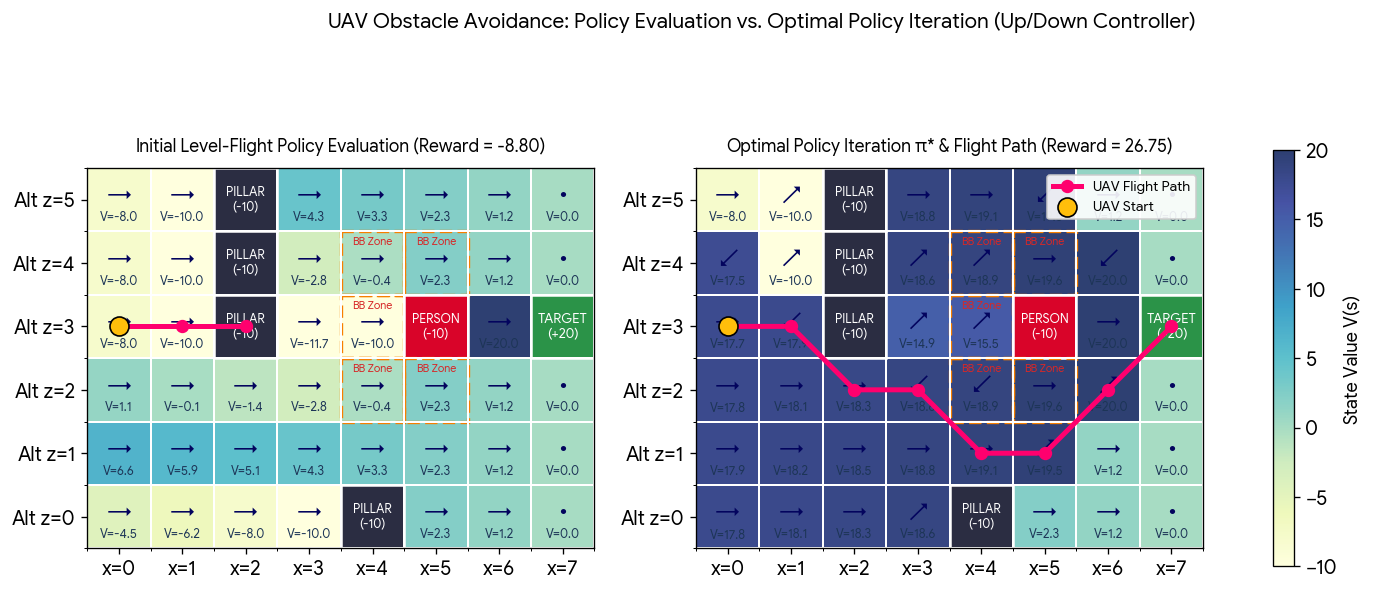


Step-by-Step Optimal UAV Flight Telemetry:
 Step t State (Row, Col) Altitude Level Controller Action Next State  Step Reward r_t
      0           (2, 0)            z=3       LEVEL  (0z)     (2, 1)             1.20
      1           (2, 1)            z=3       DN-FWD (-z)     (3, 2)             1.05
      2           (3, 2)            z=2       LEVEL  (0z)     (3, 3)             1.20
      3           (3, 3)            z=2       DN-FWD (-z)     (4, 4)             1.05
      4           (4, 4)            z=1       LEVEL  (0z)     (4, 5)             1.20
      5           (4, 5)            z=1       UP-FWD (+z)     (3, 6)             1.05
      6           (3, 6)            z=2       UP-FWD (+z)     (2, 7)            20.00


In [ ]:
def simulate_trajectory(policy, start_state=START_STATE):
    """Simulates the UAV trajectory from start_state under the given policy."""
    traj = [start_state]
    actions_taken = []
    rewards = []
    curr = start_state
    while not is_terminal(*curr):
        a = int(policy[curr])
        actions_taken.append(ACTIONS[a][0])
        curr, rew, done = step(curr[0], curr[1], a)
        rewards.append(rew)
        traj.append(curr)
        if done:
            break
    return traj, actions_taken, rewards

def plot_uav_grid(ax, V, policy, title, trajectory=None):
    """Renders the Grid-World Value Function heatmap, policy arrows, obstacles, and UAV trajectory."""
    im = ax.imshow(V, cmap="YlGnBu", vmin=-10, vmax=20, alpha=0.85)
    
    for r in range(ROWS):
        for c in range(COLS):
            cell = grid[r, c]
            if cell == 1:
                rect = patches.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#2b2d42", edgecolor="white", lw=1.5)
                ax.add_patch(rect)
                ax.text(c, r, "PILLAR\n(-10)", ha="center", va="center", color="white", fontsize=7.5, fontweight="bold")
            elif cell == 2:
                rect = patches.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#d90429", edgecolor="white", lw=1.5)
                ax.add_patch(rect)
                ax.text(c, r, "PERSON\n(-10)", ha="center", va="center", color="white", fontsize=7.5, fontweight="bold")
            elif cell == 4:
                rect = patches.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#2b9348", edgecolor="white", lw=1.5)
                ax.add_patch(rect)
                ax.text(c, r, "TARGET\n(+20)", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
            else:
                if cell == 3:
                    rect = patches.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="none", edgecolor="#f77f00", lw=2, ls="--")
                    ax.add_patch(rect)
                    ax.text(c, r - 0.33, "BB Zone", ha="center", va="center", color="#d62828", fontsize=6.5, fontweight="bold")
                
                arrow = ACTIONS[policy[r, c]][3] if not is_terminal(r, c) else "•"
                val_str = f"{V[r, c]:.1f}"
                ax.text(c, r - 0.05, arrow, ha="center", va="center", color="#03045e", fontsize=14, fontweight="bold")
                ax.text(c, r + 0.28, f"V={val_str}", ha="center", va="center", color="#1d3557", fontsize=7.5)

    # Overlay UAV flight trajectory
    if trajectory:
        tr_y = [p[0] for p in trajectory]
        tr_x = [p[1] for p in trajectory]
        ax.plot(tr_x, tr_y, color="#ff006e", linewidth=3.0, marker="o", markersize=7, label="UAV Flight Path", zorder=5)
        ax.scatter([tr_x[0]], [tr_y[0]], color="#ffbe0b", edgecolor="black", s=130, zorder=6, label="UAV Start")

    ax.set_xticks(range(COLS))
    ax.set_yticks(range(ROWS))
    ax.set_xticklabels([f"x={c}" for c in range(COLS)])
    ax.set_yticklabels([f"Alt z={ROWS-1-r}" for r in range(ROWS)])
    ax.set_xticks(np.arange(-0.5, COLS, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, ROWS, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=1.2)
    ax.set_title(title, fontsize=10.5, fontweight="bold", pad=10)
    return im

# Plot Initial Policy Evaluation (Iter 0) vs Optimal Policy (Converged)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

traj_init, _, rew_init = simulate_trajectory(pi_history[0]["policy"])
traj_opt, act_opt, rew_opt = simulate_trajectory(pi_opt)

plot_uav_grid(axes[0], pi_history[0]["V"], pi_history[0]["policy"],
              f"Initial Level-Flight Policy Evaluation (Reward = {sum(rew_init):.2f})", traj_init)
im = plot_uav_grid(axes[1], V_opt, pi_opt,
                   f"Optimal Policy Iteration π* & Flight Path (Reward = {sum(rew_opt):.2f})", traj_opt)

axes[1].legend(loc="upper right", framealpha=0.9, fontsize=8.5)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.82, label="State Value V(s)")
plt.suptitle("UAV Obstacle Avoidance: Policy Evaluation vs. Optimal Policy Iteration (Up/Down Controller)", fontsize=12.5, fontweight="bold", y=1.02)
plt.show()

# Print step-by-step optimal flight log
flight_log = pd.DataFrame({
    "Step t": range(len(act_opt)),
    "State (Row, Col)": traj_opt[:-1],
    "Altitude Level": [f"z={ROWS-1-p[0]}" for p in traj_opt[:-1]],
    "Controller Action": act_opt,
    "Next State": traj_opt[1:],
    "Step Reward r_t": rew_opt
})
print("\nStep-by-Step Optimal UAV Flight Telemetry:")
print(flight_log.to_string(index=False))